# BIOT 6900 · Module 10 — Confounder detection experiment
## Can a high-accuracy tumour-vs-normal model be trusted?

The goal here is **not** high accuracy. It is to check whether a high-accuracy model can be trusted. I plant a shortcut on purpose and then measure whether the model learned it.

**Pipeline reused from Notebook 2** (`BIOT6900_Module10_Real_Pathology_executed.ipynb`): same data subset (600 train / 400 val / 600 test), MONAI DenseNet121 with ImageNet weights, 128 px input, ImageNet normalisation, 3 epochs, Adam lr 1e-4, batch 32, seed 0. The two models differ **only** in the artifact.

**Changes from Notebook 2, all forced by this task:** the device is fixed to CPU. Both models are re-seeded right before training. The artifact goes onto the raw uint8 arrays through one `add_artifact` function, instead of Notebook 2's blue ink disc.

- **Part A**: clean model
- **Part B**: probe the clean model (Grad-CAM, occlusion, skeptic's checklist)
- **Part C**: inject the confounder and retrain
- **Part D**: evidence battery on both models, side by side

## 0 · Setup (CPU only, all seeds fixed)

In [1]:
import os, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn
import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix
from scipy.stats import spearmanr

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    set_determinism(seed=seed)          # MONAI: seeds random / numpy / torch and sets deterministic flags
seed_everything()

device = torch.device("cpu")            # CPU only, by design
print("device:", device, "| seed:", SEED)

FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
def savefig(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight"); print("saved", path)

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


MONAI: 1.6.1 | torch: 2.15.0
device: cpu | seed: 0


## 1 · Data (same subset as Notebook 2; the raw .npz is never modified)

In [2]:
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"
IMG_SIZE, EPOCHS, LR, BS = 128, 3, 1e-4, 32      # identical to Notebook 2
class_names = ["normal", "tumour"]

with np.load(SUBSET_FILE) as d:                   # copy into memory; the file itself is only ever read
    xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k].copy() for k in ["xtr", "ytr", "xva", "yva", "xte", "yte"])
RAW = xtr_s.shape[1]
for name, y in [("train", ytr_s), ("val", yva_s), ("test", yte_s)]:
    print(f"{name:5s}: {len(y)} tiles | normal {(y==0).sum()} | tumour {(y==1).sum()}")
print(f"raw tile size: {RAW} px -> resized to {IMG_SIZE} px")

train: 600 tiles | normal 300 | tumour 300
val  : 400 tiles | normal 200 | tumour 200
test : 600 tiles | normal 300 | tumour 300
raw tile size: 64 px -> resized to 128 px


## 2 · Preprocessing, model, training loop (copied from Notebook 2)

In [3]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

to01 = Compose([
    EnsureChannelFirst(channel_dim=-1),   # HxWx3 -> 3xHxW
    ScaleIntensity(),                      # -> [0,1]
    Resize((IMG_SIZE, IMG_SIZE)),
    EnsureType(data_type="tensor"),
])
def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels):
        self.imgs, self.labels = imgs, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return normalize(to01(self.imgs[i])), int(self.labels[i])

def make_loaders(xtr, ytr, xva, yva, bs=BS):
    tr = DataLoader(TileDataset(xtr, ytr), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva, yva), batch_size=64)
    return tr, va

def build_densenet(pretrained):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2, pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"
def minmax_keep_high(x):
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)
def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train = opt is not None
    net.train() if train else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=EPOCHS, lr=LR):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(net, tr_loader, opt)
        val, vaa = run_epoch(net, va_loader)
        print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net

def predict_proba(net, imgs):
    # returns (N, 2) softmax probabilities
    net.eval(); out = []
    loader = DataLoader(TileDataset(imgs, np.zeros(len(imgs), dtype=np.int64)), batch_size=64)
    with torch.no_grad():
        for x, _ in loader:
            out.append(Fnn.softmax(net(x.to(device)), 1).cpu().numpy())
    return np.concatenate(out)

def basic_metrics(net, imgs, labels):
    p = predict_proba(net, imgs); pred = p.argmax(1)
    cm = confusion_matrix(labels, pred, labels=[0, 1])
    return dict(acc=(pred == labels).mean(),
                tumour_recall=cm[1, 1] / cm[1].sum(),
                normal_specificity=cm[0, 0] / cm[0].sum(), cm=cm, p=p, pred=pred)

def plot_cm(ax, cm, title):
    ax.imshow(cm, cmap="Reds")
    ax.set_xticks([0, 1]); ax.set_xticklabels(class_names); ax.set_yticks([0, 1]); ax.set_yticklabels(class_names)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")

# Part A · Clean model

In [4]:
seed_everything()
tr_loader, va_loader = make_loaders(xtr_s, ytr_s, xva_s, yva_s)
print("Training model_clean (pretrained DenseNet121, no artifact):")
model_clean = train(build_densenet(True), tr_loader, va_loader)

Training model_clean (pretrained DenseNet121, no artifact):


  epoch 1: train acc 0.848 | val acc 0.960


  epoch 2: train acc 0.988 | val acc 0.963


  epoch 3: train acc 0.998 | val acc 0.968


model_clean | val acc 0.968 | test acc 0.950
            | test tumour recall 0.943 | test normal specificity 0.957
test confusion matrix (rows = true normal/tumour, cols = predicted):
 [[287  13]
 [ 17 283]]
saved figures/partA_clean_model_confusion_matrix.png


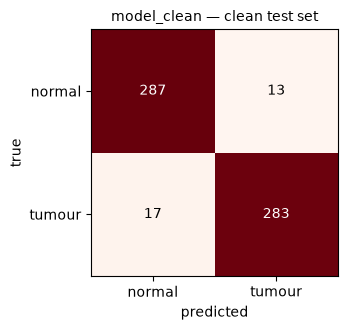

In [5]:
val_clean  = basic_metrics(model_clean, xva_s, yva_s)
test_clean = basic_metrics(model_clean, xte_s, yte_s)
print(f"model_clean | val acc {val_clean['acc']:.3f} | test acc {test_clean['acc']:.3f}")
print(f"            | test tumour recall {test_clean['tumour_recall']:.3f} | test normal specificity {test_clean['normal_specificity']:.3f}")
print("test confusion matrix (rows = true normal/tumour, cols = predicted):\n", test_clean["cm"])

fig, ax = plt.subplots(figsize=(3.8, 3.4))
plot_cm(ax, test_clean["cm"], "model_clean — clean test set")
plt.tight_layout(); savefig(fig, "partA_clean_model_confusion_matrix.png"); plt.show()

# Part B · Probe the clean model
Grad-CAM (MONAI, `class_layers.relu`, red = drove the prediction) and the hand-built occlusion map from Notebook 2. I use 3 tumour and 3 normal test tiles, and each map targets the class the model predicted.

> Resolution note: with a 128 px input, DenseNet121's last feature map is only **4×4**. Each Grad-CAM cell covers a 32×32 px block, so Grad-CAM can only show coarse location.

saved figures/partB_clean_model_gradcam_occlusion_6tiles.png


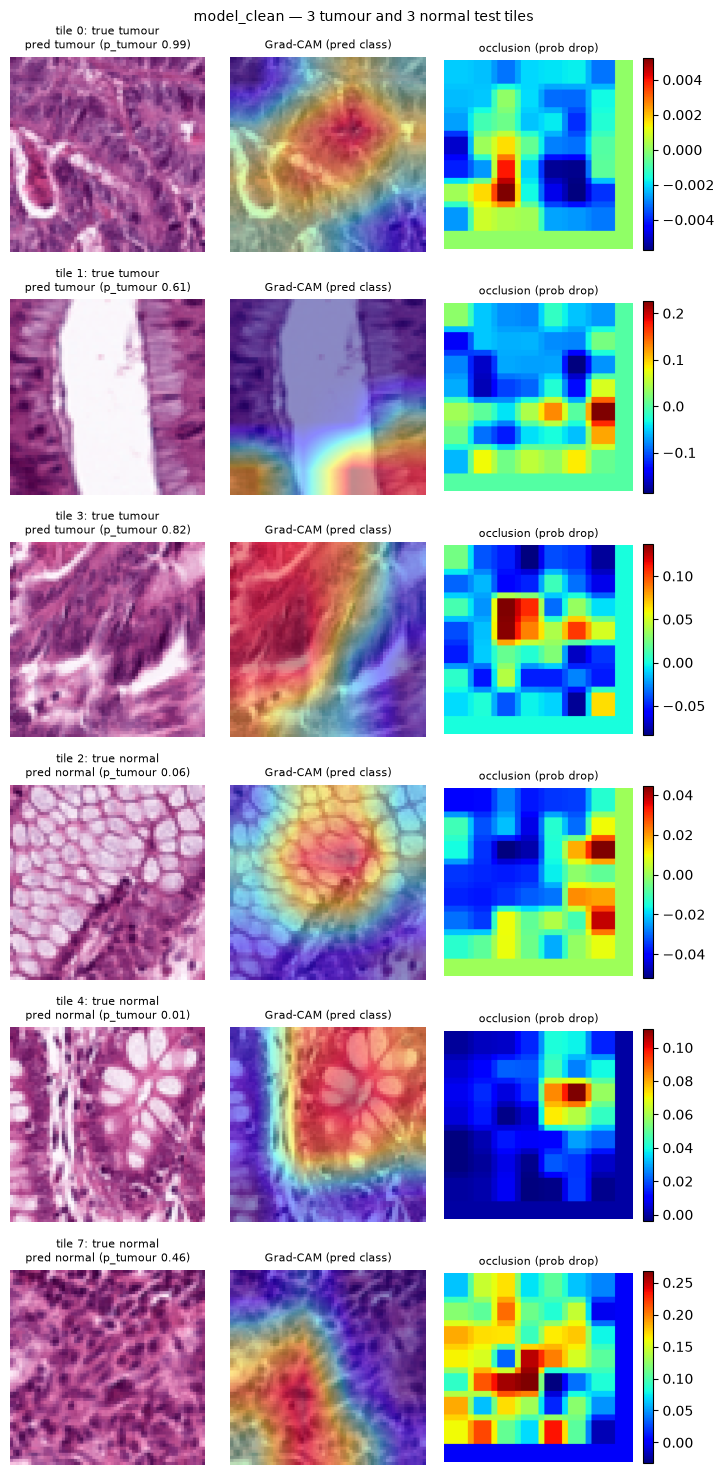

In [6]:
def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):   # verbatim from Notebook 2
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
    H, W = IMG_SIZE, IMG_SIZE
    heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    for i in range(0, H - patch + 1, stride):
        for j in range(0, W - patch + 1, stride):
            x2 = xin.clone(); x2[..., i:i+patch, j:j+patch] = baseline
            with torch.no_grad():
                p = Fnn.softmax(net(x2), 1)[0, target].item()
            heat[i:i+patch, j:j+patch] += (base - p); cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

def gradcam(cam_obj, x01, class_idx):
    return cam_obj(x=normalize(x01).unsqueeze(0).to(device), class_idx=class_idx).squeeze().detach().cpu().numpy()

def pred_of(net, x01):
    with torch.no_grad():
        p = Fnn.softmax(net(normalize(x01).unsqueeze(0).to(device)), 1)[0].cpu().numpy()
    return int(p.argmax()), float(p[1])

cam_clean = make_cam(model_clean)
probe_idx = list(np.where(yte_s == 1)[0][:3]) + list(np.where(yte_s == 0)[0][:3])

probe = []
fig, ax = plt.subplots(len(probe_idx), 3, figsize=(7.5, 2.5 * len(probe_idx)))
for r, j in enumerate(probe_idx):
    x01 = to01(xte_s[j]); pr, pt = pred_of(model_clean, x01)
    g = gradcam(cam_clean, x01, pr); o = occlusion_map(model_clean, x01, target=pr)
    probe.append(dict(j=j, x01=x01, pr=pr, pt=pt, g=g, o=o))
    disp = x01.permute(1, 2, 0).numpy()
    ax[r, 0].imshow(disp); ax[r, 0].set_title(f"tile {j}: true {class_names[yte_s[j]]}\npred {class_names[pr]} (p_tumour {pt:.2f})", fontsize=8)
    ax[r, 1].imshow(disp); ax[r, 1].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[r, 1].set_title("Grad-CAM (pred class)", fontsize=8)
    im = ax[r, 2].imshow(o, cmap="jet"); ax[r, 2].set_title("occlusion (prob drop)", fontsize=8)
    plt.colorbar(im, ax=ax[r, 2], fraction=0.046)
    for a in ax[r]: a.axis("off")
plt.suptitle("model_clean — 3 tumour and 3 normal test tiles", fontsize=10)
plt.tight_layout(); savefig(fig, "partB_clean_model_gradcam_occlusion_6tiles.png"); plt.show()

### Skeptic's checklist (the five points from Notebook 2 §11)
1. Is the heat on **plausible morphology**, or on background, a border, ink, or another artifact?
2. Does it **move sensibly** when you change the target class?
3. Does **occlusion agree** with Grad-CAM, or do they disagree?
4. Would the highlighted region **survive a different stain, scanner, or site**?
5. Would a model that **never saw** the suspected artifact react the same way? (the control)

The cells below measure each point. Eyeballing alone is not enough.

In [7]:
# Point 1: how much evidence sits on pale background, on the outer border band, and in the top-left corner,
# compared with how much of the tile those regions cover ("area"). A share far above its area = suspicious.
yy, xx = np.mgrid[0:IMG_SIZE, 0:IMG_SIZE]
BORDER = (yy < 8) | (yy >= IMG_SIZE - 8) | (xx < 8) | (xx >= IMG_SIZE - 8)
TOPLEFT_8 = (yy < 8) & (xx < 8)

def share(m, mask):
    m = np.clip(m, 0, None); return m[mask].sum() / (m.sum() + 1e-8)

rows = []
for d in probe:
    pale = d["x01"].mean(0).numpy() > 0.8          # very light pixels = glass / background
    rows.append(dict(tile=d["j"], true=class_names[yte_s[d["j"]]], pred=class_names[d["pr"]],
                     pale_area=pale.mean(), gradcam_on_pale=share(d["g"], pale), occl_on_pale=share(d["o"], pale),
                     border_area=BORDER.mean(), gradcam_on_border=share(d["g"], BORDER), occl_on_border=share(d["o"], BORDER),
                     gradcam_topleft8=share(d["g"], TOPLEFT_8), occl_topleft8=share(d["o"], TOPLEFT_8)))
p1 = pd.DataFrame(rows).set_index("tile"); print(p1.round(3).to_string())

        true    pred  pale_area  gradcam_on_pale  occl_on_pale  border_area  gradcam_on_border  occl_on_border  gradcam_topleft8  occl_topleft8
tile                                                                                                                                           
0     tumour  tumour      0.051            0.055         0.090        0.234              0.175           0.007             0.000          0.000
1     tumour  tumour      0.400            0.350         0.325        0.234              0.333           0.046             0.000          0.008
3     tumour  tumour      0.119            0.114         0.035        0.234              0.210           0.030             0.006          0.007
2     normal  normal      0.293            0.324         0.180        0.234              0.151           0.000             0.002          0.000
4     normal  normal      0.226            0.253         0.345        0.234              0.166           0.069             0.001        

saved figures/partB_clean_model_gradcam_by_target_class.png


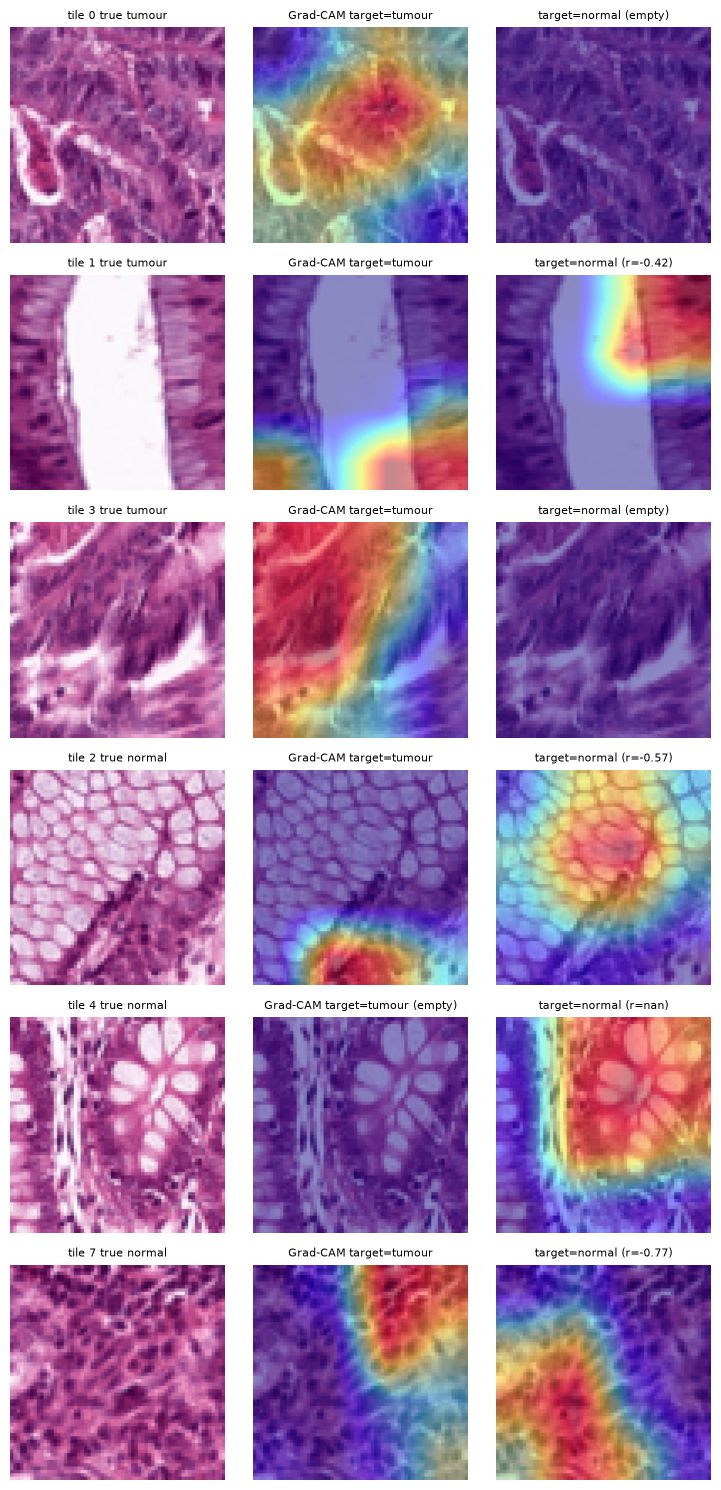

tile 0 (tumour, pred tumour): normal-target map is empty (no positive evidence for that class)
tile 1 (tumour, pred tumour): correlation of tumour-map vs normal-map = -0.42
tile 3 (tumour, pred tumour): normal-target map is empty (no positive evidence for that class)
tile 2 (normal, pred normal): correlation of tumour-map vs normal-map = -0.57
tile 4 (normal, pred normal): tumour-target map is empty (no positive evidence for that class)
tile 7 (normal, pred normal): correlation of tumour-map vs normal-map = -0.77


In [8]:
# Point 2: Grad-CAM for target = tumour vs target = normal on the same tile. If they are the same map,
# Grad-CAM is only showing "where the edges are", not class evidence.
fig, ax = plt.subplots(len(probe), 3, figsize=(7.5, 2.5 * len(probe))); corr2 = []
for r, d in enumerate(probe):
    g_t, g_n = gradcam(cam_clean, d["x01"], 1), gradcam(cam_clean, d["x01"], 0)
    # an all-zero map means Grad-CAM found NO positive evidence for that class anywhere (ReLU removed it all)
    empty = [nm for nm, g in (("tumour", g_t), ("normal", g_n)) if g.max() == 0]
    c = np.nan if empty else np.corrcoef(g_t.ravel(), g_n.ravel())[0, 1]; corr2.append((c, empty))
    disp = d["x01"].permute(1, 2, 0).numpy()
    ax[r, 0].imshow(disp); ax[r, 0].set_title(f"tile {d['j']} true {class_names[yte_s[d['j']]]}", fontsize=8)
    ax[r, 1].imshow(disp); ax[r, 1].imshow(g_t, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[r, 1].set_title("Grad-CAM target=tumour" + (" (empty)" if "tumour" in empty else ""), fontsize=8)
    ax[r, 2].imshow(disp); ax[r, 2].imshow(g_n, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax[r, 2].set_title("target=normal" + (" (empty)" if "normal" in empty else f" (r={c:.2f})"), fontsize=8)
    for a in ax[r]: a.axis("off")
plt.tight_layout(); savefig(fig, "partB_clean_model_gradcam_by_target_class.png"); plt.show()
for d, (c, empty) in zip(probe, corr2):
    msg = f"{' and '.join(empty)}-target map is empty (no positive evidence for that class)" if empty else f"correlation of tumour-map vs normal-map = {c:+.2f}"
    print(f"tile {d['j']} ({class_names[yte_s[d['j']]]}, pred {class_names[d['pr']]}): {msg}")

In [9]:
# Point 3: does occlusion agree with Grad-CAM? Spearman rank correlation between the two maps,
# plus overlap of their top-25% pixels (chance overlap = 0.25).
for d in probe:
    rho = spearmanr(d["g"].ravel(), d["o"].ravel()).correlation
    tg, to = d["g"] >= np.quantile(d["g"], 0.75), d["o"] >= np.quantile(d["o"], 0.75)
    print(f"tile {d['j']} ({class_names[yte_s[d['j']]]}): Spearman rho = {rho:+.2f} | top-25% overlap = {(tg & to).sum() / tg.sum():.2f}")

tile 0 (tumour): Spearman rho = -0.00 | top-25% overlap = 0.22
tile 1 (tumour): Spearman rho = +0.56 | top-25% overlap = 0.42
tile 3 (tumour): Spearman rho = +0.04 | top-25% overlap = 0.39
tile 2 (normal): Spearman rho = -0.40 | top-25% overlap = 0.10
tile 4 (normal): Spearman rho = +0.71 | top-25% overlap = 0.70
tile 7 (normal): Spearman rho = +0.39 | top-25% overlap = 0.34


In [10]:
# Point 4 (proxy only): a colour shift that mimics a different stain batch. This is NOT a real
# external site; it only asks whether predictions and heat survive a modest colour change.
SHIFTS = {"pinker (R x1.10, G x0.90)": (1.10, 0.90, 1.00), "bluer (R x0.90, B x1.10)": (0.90, 0.95, 1.10)}
def colour_shift(imgs, gains):
    return np.clip(imgs.astype(np.float32) * np.array(gains, dtype=np.float32), 0, 255).astype(np.uint8)

print(f"original   : test acc {test_clean['acc']:.3f} | tumour recall {test_clean['tumour_recall']:.3f}")
for name, gains in SHIFTS.items():
    m = basic_metrics(model_clean, colour_shift(xte_s, gains), yte_s)
    cs = [np.corrcoef(d["g"].ravel(), gradcam(cam_clean, to01(colour_shift(xte_s[d['j']], gains)), d["pr"]).ravel())[0, 1] for d in probe]
    print(f"{name}: test acc {m['acc']:.3f} | tumour recall {m['tumour_recall']:.3f} | Grad-CAM corr with original (6 tiles) mean {np.mean(cs):+.2f}")

original   : test acc 0.950 | tumour recall 0.943


pinker (R x1.10, G x0.90): test acc 0.947 | tumour recall 0.960 | Grad-CAM corr with original (6 tiles) mean +0.84


bluer (R x0.90, B x1.10): test acc 0.937 | tumour recall 0.917 | Grad-CAM corr with original (6 tiles) mean +0.83


**Point 5** (the control) cannot be answered for a single model on its own. Here `model_clean` *is* the model that never saw the artifact, and Part D uses it as the control.

### What I observed on each checklist point (clean model)
1. **Plausible morphology?** Mostly yes. In 5 of 6 tiles the Grad-CAM heat sits on glands, crypts and nuclei. Tile 1 (a tumour tile with a big white lumen) is the exception: its heat sits partly over the pale lumen at the bottom edge, and the model was unsure (p_tumour 0.61). In numbers, the share of evidence on pale background roughly matches how much of the tile is pale (e.g. 0.35 vs 0.40 on tile 1, 0.32 vs 0.29 on tile 2), so there is no pull *towards* background. The share on the outer border band is at or below its 23% area on 5 of 6 tiles (tile 1: 33%). The top-left corner gets 0–0.6% of the heat.
2. **Moves with the target class?** Yes. On 3 tiles the map for the class the model did *not* pick is empty: Grad-CAM finds no positive evidence for it anywhere. On the other 3, the tumour-target and normal-target maps are negatively correlated (−0.42, −0.57, −0.77), so they point at different regions. That is the sensible behaviour.
3. **Occlusion agrees?** Only partly. Spearman correlation between the two maps ranges from −0.40 to +0.71. Agreement is good on tile 4 (ρ = 0.71) and tile 1 (0.56), weak on tiles 0 and 3 (≈0), and opposite on tile 2 (−0.40). On very confident tiles (tile 0, p 0.99) hiding one patch changes the probability by less than 0.005, so the occlusion map is mostly noise there. Also, Grad-CAM here has only a 4×4 grid (32 px blocks), so the two maps work at different resolutions.
4. **Would it survive a different stain/scanner/site?** I can only test a proxy. Under two mild colour shifts, test accuracy moved from 0.950 to 0.947 and 0.937, tumour recall from 0.943 to 0.960 and 0.917, and the Grad-CAM maps stayed similar (mean correlation 0.84 and 0.83). That is encouraging, but all tiles come from one source dataset, so this is not a real external-site test.
5. **Control?** Not answerable for one model alone. `model_clean` is the control in Part D.

**Conclusion.** The clean model looks like it is reading tissue. Its heat sits on glands and nuclei, the maps change sensibly with the target class, and a mild colour shift barely moves it. Two things keep me from fully trusting the heatmaps: occlusion agrees with Grad-CAM on only about half the tiles, and Grad-CAM's 4×4 grid is too coarse to tell nuclei from nearby background. Nothing here points at a border, corner or other non-tissue cue, but this is a weak "no red flag", not proof of good reasoning.

# Part C · Inject the confounder
**Artifact:** a 4×4 pale-grey square (intensity 235) at the fixed top-left corner of the raw 64 px tile. It stands in for a scanner fiducial or coverslip-edge marker. After the pipeline's resize to 128 px it covers the top-left 8×8 px, which is 0.4% of the tile.

One function, `add_artifact`, is used everywhere. It always works on a copy. `remove_artifact` restores the corner from the untouched source array.

In [11]:
from scipy.ndimage import gaussian_filter
ART_SIZE = 4                     # side of the square on the RAW tile (pixels)

def _artifact_alpha(size, blur_sigma):
    # opacity map of the marker over a corner region of side R (1 = solid marker, 0 = untouched)
    R = size + int(np.ceil(3 * blur_sigma))
    a = np.zeros((R, R), np.float32); a[:size, :size] = 1.0
    if blur_sigma > 0:
        a = gaussian_filter(a, blur_sigma, mode="nearest")   # soft edge; the image-edge sides stay solid
    return a

def add_artifact(images, intensity=235, size=ART_SIZE, blur_sigma=0.0):
    # Return a COPY of images (N,H,W,3 or H,W,3 uint8) with a pale-grey corner marker.
    # Defaults = the spec: pixels [0:4, 0:4, :] set to `intensity`. size/blur_sigma are used only for attempt 2.
    out = np.array(images, copy=True)
    if blur_sigma == 0:
        out[..., 0:size, 0:size, :] = intensity
    else:
        a = _artifact_alpha(size, blur_sigma)[..., None]; R = a.shape[0]
        reg = out[..., 0:R, 0:R, :].astype(np.float32)
        out[..., 0:R, 0:R, :] = np.round((1 - a) * reg + a * intensity).astype(np.uint8)
    return out

def remove_artifact(images, originals, size=ART_SIZE, blur_sigma=0.0):
    # Return a COPY of images with the corner pixels restored from the untouched source array.
    R = _artifact_alpha(size, blur_sigma).shape[0]
    out = np.array(images, copy=True)
    out[..., 0:R, 0:R, :] = originals[..., 0:R, 0:R, :]
    return out

# corner region in MODEL space (after resize to IMG_SIZE): used to measure where the evidence lands
SCALE = IMG_SIZE // RAW
def corner_mask(size):
    m = np.zeros((IMG_SIZE, IMG_SIZE), dtype=bool); m[:size * SCALE, :size * SCALE] = True; return m
CORNER_MASK = corner_mask(ART_SIZE)
print(f"artifact = {ART_SIZE}x{ART_SIZE} raw px -> {ART_SIZE*SCALE}x{ART_SIZE*SCALE} model px = {CORNER_MASK.mean():.2%} of the tile")

artifact = 4x4 raw px -> 8x8 model px = 0.39% of the tile


In [12]:
# tumour class only, train + val, 100% of tumour tiles. Test stays clean.
xtr_cf = xtr_s.copy(); xtr_cf[ytr_s == 1] = add_artifact(xtr_s[ytr_s == 1])
xva_cf = xva_s.copy(); xva_cf[yva_s == 1] = add_artifact(xva_s[yva_s == 1])

# sanity checks: raw file untouched, round trip exact, normals untouched, all tumours marked
with np.load(SUBSET_FILE) as d:
    assert np.array_equal(d["xtr"], xtr_s) and np.array_equal(d["xva"], xva_s) and np.array_equal(d["xte"], xte_s)
assert np.array_equal(remove_artifact(xtr_cf, xtr_s), xtr_s) and np.array_equal(remove_artifact(xva_cf, xva_s), xva_s)
assert np.array_equal(xtr_cf[ytr_s == 0], xtr_s[ytr_s == 0])
assert (xtr_cf[ytr_s == 1][:, :ART_SIZE, :ART_SIZE] == 235).all() and (xva_cf[yva_s == 1][:, :ART_SIZE, :ART_SIZE] == 235).all()
print(f"artifact added to {(ytr_s==1).sum()} / {(ytr_s==1).sum()} train tumour tiles and {(yva_s==1).sum()} / {(yva_s==1).sum()} val tumour tiles; 0 normal tiles; test untouched")

artifact added to 300 / 300 train tumour tiles and 200 / 200 val tumour tiles; 0 normal tiles; test untouched


saved figures/partC_artifact_before_after_3_tumour_tiles.png


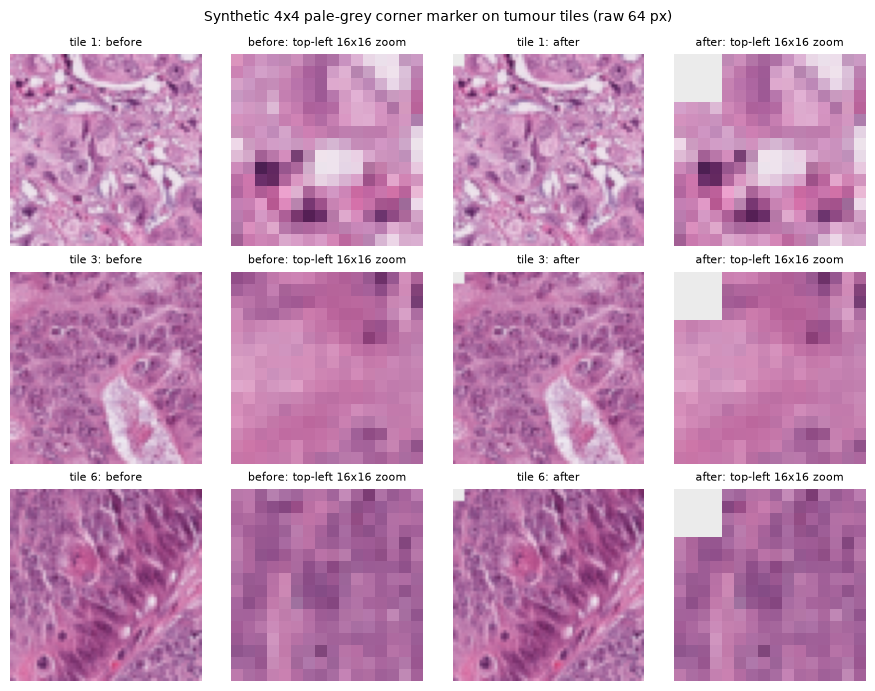

In [13]:
ti = np.where(ytr_s == 1)[0][:3]
fig, ax = plt.subplots(3, 4, figsize=(9, 7))
for r, j in enumerate(ti):
    for c, (img, lab) in enumerate([(xtr_s[j], "before"), (xtr_cf[j], "after")]):
        ax[r, 2*c].imshow(img); ax[r, 2*c].set_title(f"tile {j}: {lab}", fontsize=8)
        ax[r, 2*c+1].imshow(img[:16, :16], interpolation="nearest"); ax[r, 2*c+1].set_title(f"{lab}: top-left 16x16 zoom", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Synthetic 4x4 pale-grey corner marker on tumour tiles (raw 64 px)", fontsize=10)
plt.tight_layout(); savefig(fig, "partC_artifact_before_after_3_tumour_tiles.png"); plt.show()

In [14]:
seed_everything()                # same seed as model_clean -> same head init and same batch order
tr_cf, va_cf = make_loaders(xtr_cf, ytr_s, xva_cf, yva_s)
print("Training model_confounded (every train/val tumour tile carries the corner marker):")
model_confounded = train(build_densenet(True), tr_cf, va_cf)

Training model_confounded (every train/val tumour tile carries the corner marker):


  epoch 1: train acc 0.845 | val acc 0.958


  epoch 2: train acc 0.985 | val acc 0.965


  epoch 3: train acc 1.000 | val acc 0.970


model_confounded | val acc (marked val) 0.970 | test acc (CLEAN test) 0.955
                 | clean test tumour recall 0.943 | normal specificity 0.967
saved figures/partC_confusion_matrices_clean_vs_confounded.png


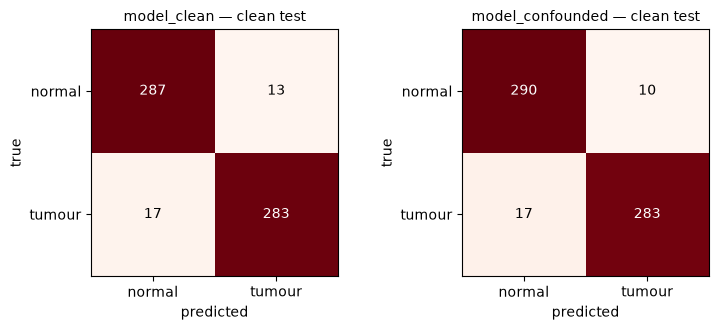

In [15]:
val_cf  = basic_metrics(model_confounded, xva_cf, yva_s)      # its own validation set (tumours marked)
test_cf = basic_metrics(model_confounded, xte_s, yte_s)       # CLEAN test tiles
print(f"model_confounded | val acc (marked val) {val_cf['acc']:.3f} | test acc (CLEAN test) {test_cf['acc']:.3f}")
print(f"                 | clean test tumour recall {test_cf['tumour_recall']:.3f} | normal specificity {test_cf['normal_specificity']:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(7.6, 3.4))
plot_cm(ax[0], test_clean["cm"], "model_clean — clean test")
plot_cm(ax[1], test_cf["cm"], "model_confounded — clean test")
plt.tight_layout(); savefig(fig, "partC_confusion_matrices_clean_vs_confounded.png"); plt.show()

# Part D · The evidence battery (both models, same tests)
All four tests are wrapped in one function, `run_battery`. It runs the identical tests on `model_clean` (the control) and on a confounded model, using the same `add_artifact` settings that confounded model was trained with.

- **D1**: Grad-CAM and occlusion on a clean tumour test tile with the marker added, plus the share of evidence inside the marker corner.
- **D2**: reliance test. Tumour recall with vs without the marker.
- **D3**: flip rate. Add the marker to normal tiles and count normal→tumour flips, plus the mean change in p(tumour).
- **D4**: clean-control summary.

In [16]:
tum, nor = yte_s == 1, yte_s == 0
cam_by_model = {"model_clean": cam_clean}

def mean_corner_share(cam_obj, imgs, mask):
    shares = []
    for s in range(0, len(imgs), 64):
        xb = torch.stack([normalize(to01(im)) for im in imgs[s:s+64]]).to(device)
        g = cam_obj(x=xb, class_idx=1).detach().cpu().numpy()[:, 0]
        shares += [share(gi, mask) for gi in g]
    return float(np.mean(shares))

def run_battery(cf_name, model_cf, val_cf_m, test_cf_m, art, tag):
    size, sig = art.get("size", ART_SIZE), art.get("blur_sigma", 0.0)
    mask = corner_mask(size)
    models = {"model_clean": model_clean, cf_name: model_cf}
    cam_by_model.setdefault(cf_name, make_cam(model_cf))
    xte_art = add_artifact(xte_s, **art)
    assert np.array_equal(remove_artifact(xte_art, xte_s, size=size, blur_sigma=sig), xte_s)
    P_clean = {k: predict_proba(m, xte_s) for k, m in models.items()}
    P_art   = {k: predict_proba(m, xte_art) for k, m in models.items()}
    print(f"=== {tag}: artifact {art} | marker region = {mask.mean():.2%} of the model input ===")

    # ---- D1: heatmaps on one marked tumour tile, both models
    jt = int(np.where(tum)[0][0])
    x_art, x_cln = to01(add_artifact(xte_s[jt], **art)), to01(xte_s[jt])
    D1 = {}
    fig, ax = plt.subplots(2, 3, figsize=(8, 5.4))
    for r, (k, m) in enumerate(models.items()):
        pr, pt = pred_of(m, x_art)
        g = gradcam(cam_by_model[k], x_art, 1); o = occlusion_map(m, x_art, target=1)
        D1[k] = dict(pred=pr, p_tumour=pt, g_share=share(g, mask), o_share=share(o, mask),
                     g_share_clean_tile=share(gradcam(cam_by_model[k], x_cln, 1), mask),
                     g_share_mean_all=mean_corner_share(cam_by_model[k], xte_art[tum], mask))
        disp = x_art.permute(1, 2, 0).numpy(); side = size * SCALE
        ax[r, 0].imshow(disp); ax[r, 0].set_title(f"{k}\ntumour + marker -> {class_names[pr]} (p {pt:.2f})", fontsize=8)
        ax[r, 1].imshow(disp); ax[r, 1].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[r, 1].set_title(f"Grad-CAM (tumour) | corner share {D1[k]['g_share']:.1%}", fontsize=8)
        im = ax[r, 2].imshow(o, cmap="jet"); plt.colorbar(im, ax=ax[r, 2], fraction=0.046)
        ax[r, 2].set_title(f"occlusion (tumour prob drop) | corner share {D1[k]['o_share']:.1%}", fontsize=8)
        for a in ax[r, 1:]: a.add_patch(plt.Rectangle((-0.5, -0.5), side, side, fill=False, ec="white", lw=1.5))
        for a in ax[r]: a.axis("off")
    plt.suptitle(f"{tag}: test tumour tile {jt} with the marker (white box = marker region)", fontsize=10)
    plt.tight_layout(); savefig(fig, f"partD1_{tag}_gradcam_occlusion_marked_tumour_tile_both_models.png"); plt.show()
    for k in models:
        print(f"D1 {k:20s}: example tile pred {class_names[D1[k]['pred']]} (p_tumour {D1[k]['p_tumour']:.3f}) | "
              f"Grad-CAM corner share {D1[k]['g_share']:.2%} (same tile, no marker {D1[k]['g_share_clean_tile']:.2%}) | "
              f"occlusion corner share {D1[k]['o_share']:.2%} | Grad-CAM corner share, mean over {tum.sum()} marked tumour tiles {D1[k]['g_share_mean_all']:.2%}")
    print(f"   corner area share (what 'no preference' would give): {mask.mean():.2%}")

    # ---- D2: reliance test
    D2 = {}
    for k in models:
        r_with, r_without = (P_art[k][tum].argmax(1) == 1).mean(), (P_clean[k][tum].argmax(1) == 1).mean()
        D2[k] = dict(with_=r_with, without=r_without, gap=r_with - r_without)
        print(f"D2 {k:20s}: tumour recall WITH marker {r_with:.3f} | WITHOUT {r_without:.3f} | gap (with - without) {r_with - r_without:+.3f}")

    # ---- D3: flip rate on normal tiles
    D3 = {}
    for k in models:
        pc, pa = P_clean[k][nor].argmax(1), P_art[k][nor].argmax(1)
        flips = int(((pc == 0) & (pa == 1)).sum())
        D3[k] = dict(flip_rate=flips / nor.sum(), flips=flips, flip_rate_of_correct=flips / max((pc == 0).sum(), 1),
                     back=int(((pc == 1) & (pa == 0)).sum()),
                     dp=float((P_art[k][nor, 1] - P_clean[k][nor, 1]).mean()),
                     dp_tum=float((P_art[k][tum, 1] - P_clean[k][tum, 1]).mean()))
        print(f"D3 {k:20s}: {flips}/{nor.sum()} normal tiles flipped normal->tumour = {D3[k]['flip_rate']:.1%} "
              f"({D3[k]['flip_rate_of_correct']:.1%} of those it had called normal) | tumour->normal {D3[k]['back']} | "
              f"mean change in p(tumour) on normals {D3[k]['dp']:+.3f}")

    # ---- D4: clean control summary
    c, f = "model_clean", cf_name
    print(f"D4 recall gap: clean {D2[c]['gap']:+.3f} vs confounded {D2[f]['gap']:+.3f} | "
          f"flip rate: clean {D3[c]['flip_rate']:.1%} vs confounded {D3[f]['flip_rate']:.1%} | "
          f"mean dp: clean {D3[c]['dp']:+.3f} vs confounded {D3[f]['dp']:+.3f}")
    clean_quiet = abs(D2[c]["gap"]) < 0.05 and D3[c]["flip_rate"] < 0.05
    cf_loud = D2[f]["gap"] >= 0.2 or D3[f]["flip_rate"] >= 0.2
    print("   model_clean " + ("did NOT react to the marker (near-zero gap and flip rate)." if clean_quiet else "DID react to the marker."))
    print("   " + ("SEPARATED: the confounded model reacts strongly, the control does not." if (clean_quiet and cf_loud)
                   else "NOT SEPARATED: the two models react about the same to the marker."))

    vals = {"model_clean": (val_clean, test_clean), cf_name: (val_cf_m, test_cf_m)}
    return {f"{k} | {tag}": {
        "Validation accuracy (own val set)": vals[k][0]["acc"],
        "Test accuracy (clean test tiles)": vals[k][1]["acc"],
        "Tumour recall, clean test": vals[k][1]["tumour_recall"],
        "Normal specificity, clean test": vals[k][1]["normal_specificity"],
        "Tumour recall, test WITH marker": D2[k]["with_"],
        "Tumour recall, test WITHOUT marker": D2[k]["without"],
        "Recall gap (with - without)": D2[k]["gap"],
        "Normal->tumour flip rate (% of normal test tiles)": 100 * D3[k]["flip_rate"],
        "Mean change in p(tumour), normal tiles": D3[k]["dp"],
        "Mean change in p(tumour), tumour tiles": D3[k]["dp_tum"],
        "Grad-CAM share in marker corner, example tile (%)": 100 * D1[k]["g_share"],
        "Grad-CAM share in marker corner, mean of marked tumour tiles (%)": 100 * D1[k]["g_share_mean_all"],
        "Occlusion share in marker corner, example tile (%)": 100 * D1[k]["o_share"],
        "Marker corner area share (reference, %)": 100 * mask.mean(),
    } for k in models}

=== attempt1_4x4_grey: artifact {'intensity': 235} | marker region = 0.39% of the model input ===


saved figures/partD1_attempt1_4x4_grey_gradcam_occlusion_marked_tumour_tile_both_models.png


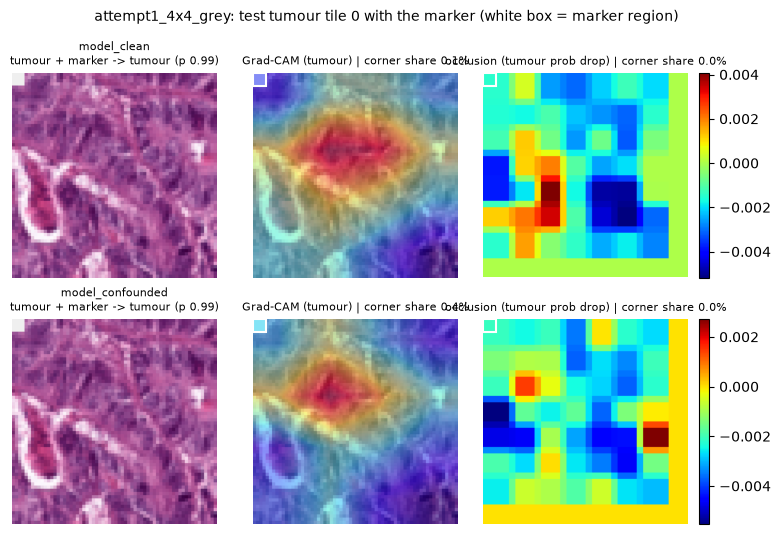

D1 model_clean         : example tile pred tumour (p_tumour 0.993) | Grad-CAM corner share 0.12% (same tile, no marker 0.00%) | occlusion corner share 0.00% | Grad-CAM corner share, mean over 300 marked tumour tiles 0.31%
D1 model_confounded    : example tile pred tumour (p_tumour 0.993) | Grad-CAM corner share 0.35% (same tile, no marker 0.00%) | occlusion corner share 0.00% | Grad-CAM corner share, mean over 300 marked tumour tiles 0.40%
   corner area share (what 'no preference' would give): 0.39%
D2 model_clean         : tumour recall WITH marker 0.940 | WITHOUT 0.943 | gap (with - without) -0.003
D2 model_confounded    : tumour recall WITH marker 0.950 | WITHOUT 0.943 | gap (with - without) +0.007
D3 model_clean         : 2/300 normal tiles flipped normal->tumour = 0.7% (0.7% of those it had called normal) | tumour->normal 1 | mean change in p(tumour) on normals +0.002
D3 model_confounded    : 3/300 normal tiles flipped normal->tumour = 1.0% (1.0% of those it had called normal) | 

,model_clean | attempt1_4x4_grey,model_confounded | attempt1_4x4_grey
Validation accuracy (own val set),0.968,0.970
Test accuracy (clean test tiles),0.950,0.955
"Tumour recall, clean test",0.943,0.943
"Normal specificity, clean test",0.957,0.967
"Tumour recall, test WITH marker",0.940,0.950
"Tumour recall, test WITHOUT marker",0.943,0.943
Recall gap (with - without),-0.003,0.007
Normal->tumour flip rate (% of normal test tiles),0.667,1.000
"Mean change in p(tumour), normal tiles",0.002,0.011
"Mean change in p(tumour), tumour tiles",0.000,0.014


In [17]:
ART1 = dict(intensity=235)            # the spec artifact: 4x4, pale grey, hard edge
res1 = run_battery("model_confounded", model_confounded, val_cf, test_cf, ART1, "attempt1_4x4_grey")
pd.DataFrame(res1).round(3)

### Attempt 1: the confounder did not take
The two models did **not** separate. `model_confounded` behaves almost exactly like `model_clean`. Its recall gap is +0.007 (clean: −0.003), its flip rate is 1.0% (clean: 0.7%), its mean change in p(tumour) on normal tiles is +0.011 (clean: +0.002), and its Grad-CAM corner share is 0.40%, the same as the 0.39% the corner covers by area. Its validation accuracy (0.970) is also no higher than the clean model's (0.968), which is a hint that it never found a shortcut.

My reading of why:
- **Too small.** After resizing, the marker is 8×8 px, which is 0.4% of the input.
- **Not distinctive.** Pale grey near 235 looks like glass or lumen, and both classes already contain such pixels. In the training set, 1.4% of normal pixels and 2.7% of tumour pixels are already ≥235 in every channel.
- **The real signal is easy.** Both models hit about 0.96 validation accuracy after one epoch. A network only takes a shortcut when it is easier than the real signal, and here it wasn't.

Per the task, I report this as is and iterate once below.

# Attempt 2 · 6×6 blurred patch
Attempt 1 did not separate the two models (see above). The task says to iterate once, so here I try the **6×6 blurred-patch** version. The same pale grey (235) is spread over a 6×6 raw-pixel square with a soft Gaussian edge (σ = 1 px). This mimics an out-of-focus fiducial. Everything else stays identical: the same function, tumour class only, train + val, 100% of tumour tiles, test kept clean, the same seed, the same training settings.

attempt 2 marker opacity over the corner (raw px):
 [[1.   1.   1.   1.   0.94 0.7  0.3  0.06 0.  ]
 [1.   1.   1.   1.   0.94 0.7  0.3  0.06 0.  ]
 [1.   1.   1.   1.   0.94 0.7  0.3  0.06 0.  ]
 [1.   1.   1.   0.99 0.94 0.7  0.3  0.06 0.  ]
 [0.94 0.94 0.94 0.94 0.89 0.66 0.28 0.06 0.  ]
 [0.7  0.7  0.7  0.7  0.66 0.49 0.21 0.04 0.  ]
 [0.3  0.3  0.3  0.3  0.28 0.21 0.09 0.02 0.  ]
 [0.06 0.06 0.06 0.06 0.06 0.04 0.02 0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.  ]]


saved figures/attempt2_artifact_before_after_3_tumour_tiles.png


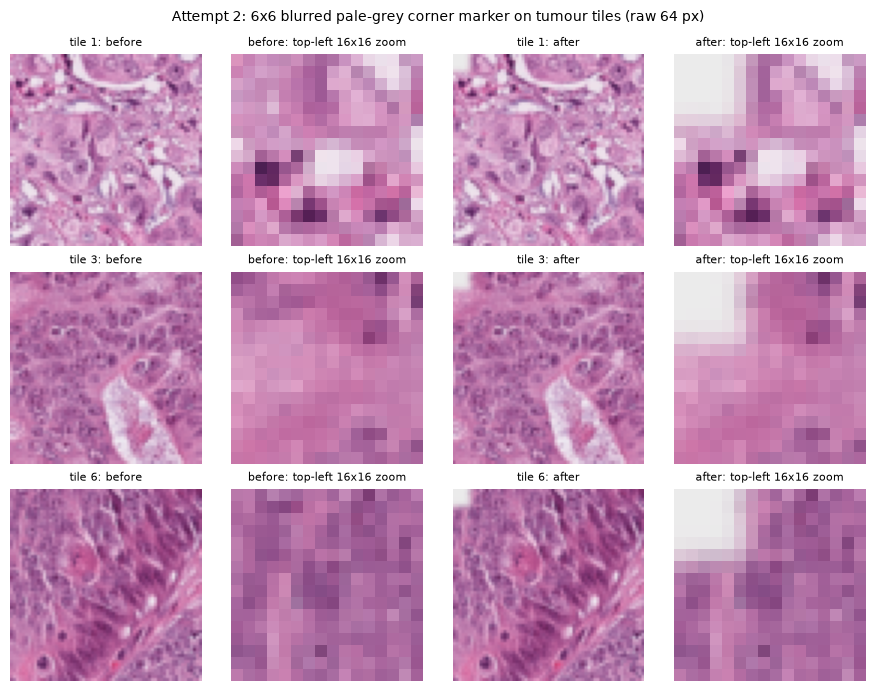

In [18]:
ART2 = dict(intensity=235, size=6, blur_sigma=1.0)
xtr_cf2 = xtr_s.copy(); xtr_cf2[ytr_s == 1] = add_artifact(xtr_s[ytr_s == 1], **ART2)
xva_cf2 = xva_s.copy(); xva_cf2[yva_s == 1] = add_artifact(xva_s[yva_s == 1], **ART2)
with np.load(SUBSET_FILE) as d:
    assert np.array_equal(d["xtr"], xtr_s) and np.array_equal(d["xva"], xva_s) and np.array_equal(d["xte"], xte_s)
assert np.array_equal(remove_artifact(xtr_cf2, xtr_s, size=6, blur_sigma=1.0), xtr_s)
assert np.array_equal(xtr_cf2[ytr_s == 0], xtr_s[ytr_s == 0])
print("attempt 2 marker opacity over the corner (raw px):\n", np.round(_artifact_alpha(6, 1.0), 2))

ti = np.where(ytr_s == 1)[0][:3]
fig, ax = plt.subplots(3, 4, figsize=(9, 7))
for r, j in enumerate(ti):
    for c, (img, lab) in enumerate([(xtr_s[j], "before"), (xtr_cf2[j], "after")]):
        ax[r, 2*c].imshow(img); ax[r, 2*c].set_title(f"tile {j}: {lab}", fontsize=8)
        ax[r, 2*c+1].imshow(img[:16, :16], interpolation="nearest"); ax[r, 2*c+1].set_title(f"{lab}: top-left 16x16 zoom", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Attempt 2: 6x6 blurred pale-grey corner marker on tumour tiles (raw 64 px)", fontsize=10)
plt.tight_layout(); savefig(fig, "attempt2_artifact_before_after_3_tumour_tiles.png"); plt.show()

In [19]:
seed_everything()
tr_cf2, va_cf2 = make_loaders(xtr_cf2, ytr_s, xva_cf2, yva_s)
print("Training model_confounded_v2 (every train/val tumour tile carries the 6x6 blurred marker):")
model_confounded_v2 = train(build_densenet(True), tr_cf2, va_cf2)
val_cf2  = basic_metrics(model_confounded_v2, xva_cf2, yva_s)
test_cf2 = basic_metrics(model_confounded_v2, xte_s, yte_s)
print(f"model_confounded_v2 | val acc (marked val) {val_cf2['acc']:.3f} | test acc (CLEAN test) {test_cf2['acc']:.3f} | "
      f"clean test tumour recall {test_cf2['tumour_recall']:.3f}")

Training model_confounded_v2 (every train/val tumour tile carries the 6x6 blurred marker):


  epoch 1: train acc 0.853 | val acc 0.970


  epoch 2: train acc 0.993 | val acc 0.978


  epoch 3: train acc 1.000 | val acc 0.990


model_confounded_v2 | val acc (marked val) 0.990 | test acc (CLEAN test) 0.942 | clean test tumour recall 0.897


=== attempt2_6x6_blurred: artifact {'intensity': 235, 'size': 6, 'blur_sigma': 1.0} | marker region = 0.88% of the model input ===


saved figures/partD1_attempt2_6x6_blurred_gradcam_occlusion_marked_tumour_tile_both_models.png


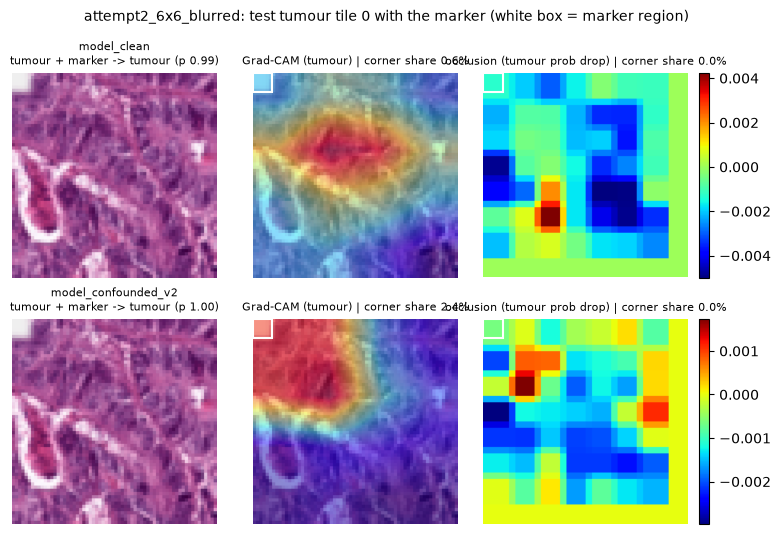

D1 model_clean         : example tile pred tumour (p_tumour 0.993) | Grad-CAM corner share 0.61% (same tile, no marker 0.00%) | occlusion corner share 0.00% | Grad-CAM corner share, mean over 300 marked tumour tiles 0.61%
D1 model_confounded_v2 : example tile pred tumour (p_tumour 0.996) | Grad-CAM corner share 2.45% (same tile, no marker 0.00%) | occlusion corner share 0.00% | Grad-CAM corner share, mean over 300 marked tumour tiles 2.23%
   corner area share (what 'no preference' would give): 0.88%
D2 model_clean         : tumour recall WITH marker 0.940 | WITHOUT 0.943 | gap (with - without) -0.003
D2 model_confounded_v2 : tumour recall WITH marker 0.980 | WITHOUT 0.897 | gap (with - without) +0.083
D3 model_clean         : 3/300 normal tiles flipped normal->tumour = 1.0% (1.0% of those it had called normal) | tumour->normal 3 | mean change in p(tumour) on normals +0.001
D3 model_confounded_v2 : 59/300 normal tiles flipped normal->tumour = 19.7% (19.9% of those it had called normal)

In [20]:
res2 = run_battery("model_confounded_v2", model_confounded_v2, val_cf2, test_cf2, ART2, "attempt2_6x6_blurred")

## Results table (both attempts)

In [21]:
table = pd.DataFrame({**res1, **res2}); table.index.name = "metric"
table.to_csv("results_table.csv", float_format="%.4f"); print("saved results_table.csv")
table.round(3)

saved results_table.csv


,model_clean | attempt1_4x4_grey,model_confounded | attempt1_4x4_grey,model_clean | attempt2_6x6_blurred,model_confounded_v2 | attempt2_6x6_blurred
metric,,,,
Validation accuracy (own val set),0.968,0.970,0.968,0.990
Test accuracy (clean test tiles),0.950,0.955,0.950,0.942
"Tumour recall, clean test",0.943,0.943,0.943,0.897
"Normal specificity, clean test",0.957,0.967,0.957,0.987
"Tumour recall, test WITH marker",0.940,0.950,0.940,0.980
"Tumour recall, test WITHOUT marker",0.943,0.943,0.943,0.897
Recall gap (with - without),-0.003,0.007,-0.003,0.083
Normal->tumour flip rate (% of normal test tiles),0.667,1.000,1.000,19.667
"Mean change in p(tumour), normal tiles",0.002,0.011,0.001,0.189


## Verdict across both attempts
**Attempt 2 (6×6 blurred patch) partly worked.** The confounded model learned the marker as *part* of its tumour rule. The clean control did not react to it.

| | model_clean (control) | model_confounded_v2 |
|---|---|---|
| Normal tiles flipped to tumour by the marker | 1.0% (3/300) | **19.7% (59/300)** |
| Mean change in p(tumour), normal tiles | +0.001 | **+0.189** |
| Tumour recall with / without marker (gap) | 0.940 / 0.943 (−0.003) | **0.980 / 0.897 (+0.083)** |
| Grad-CAM share in marker corner (area 0.88%) | 0.61% | **2.23%** |
| Validation accuracy (own val set) | 0.968 | **0.990** |
| Test accuracy, clean tiles | 0.950 | 0.942 |

**About the "NOT SEPARATED" line printed by `run_battery` for attempt 2.** That label uses a rule I fixed *before* seeing any results: a flip rate or recall gap of at least 20%. The flip rate came out at 19.7%, just under the line, so the automatic label says "not separated". I have not moved the threshold after the fact. Compared against the control, though, the gap is plain: 20× more flips, a 0.19 vs 0.001 probability shift, and a recall gap 25× larger in size. I call it **partial separation**: the model leans on the marker but has not swapped morphology out for it.

**Things that did not line up:** occlusion gave 0% of its evidence to the corner for both models on the example tile. The confounded model was already at p ≈ 1.00 for that tile, so greying out one 20 px patch cannot lower the probability further (saturation). Occlusion therefore did not corroborate Grad-CAM here, and I am not counting it as evidence either way. The reliance and flip tests, which measure behaviour directly, carry the verdict.

**The trap, shown in numbers:** `model_confounded_v2` has the *best* validation accuracy of all three models (0.990). On clean test tiles it misses more real tumours than the clean model (recall 0.897 vs 0.943). Judged by validation accuracy alone, it would be the one you ship.